In [2]:
import kagglehub
import os

print("Downloading PaySim dataset...")

paysim_path = kagglehub.dataset_download("ealaxi/paysim1")

print(f"Path to dataset files: {paysim_path}")
print(f"Files in path: {os.listdir(paysim_path)}")

100%|██████████| 178M/178M [00:10<00:00, 18.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ealaxi/paysim1/versions/2
Files in path: ['PS_20174392719_1491204439457_log.csv']


In [3]:
# =========================
# Step 2: Load & Inspect PaySim Schema
# =========================

import pandas as pd
import numpy as np

DATA_PATH = "/root/.cache/kagglehub/datasets/ealaxi/paysim1/versions/2/PS_20174392719_1491204439457_log.csv"

# --- Load ---
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# --- Basic preview ---
print("\nDtypes:")
print(df.dtypes)

print("\nHead:")
display(df.head(3))

# --- Missing values ---
na = df.isna().sum().sort_values(ascending=False)
print("\nMissing values (non-zero only):")
display(na[na > 0])

# --- Target distribution ---
assert "isFraud" in df.columns, "Column 'isFraud' not found."
fraud_counts = df["isFraud"].value_counts().sort_index()
print("\nTarget distribution (0=normal, 1=fraud):")
print(fraud_counts)
print("Fraud rate:", float(fraud_counts.get(1, 0) / len(df)))

# --- Basic time axis check ---
assert "step" in df.columns, "Column 'step' not found. PaySim usually uses 'step' as time."
print("\nstep min/max:", int(df["step"].min()), int(df["step"].max()))
print("Unique steps:", int(df["step"].nunique()))

# --- Transaction type distribution (important for later feature engineering) ---
if "type" in df.columns:
    print("\nTransaction type distribution:")
    print(df["type"].value_counts())



Shape: (6362620, 11)
Columns: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Dtypes:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Head:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0



Missing values (non-zero only):


,0



Target distribution (0=normal, 1=fraud):
isFraud
0    6354407
1       8213
Name: count, dtype: int64
Fraud rate: 0.001290820448180152

step min/max: 1 743
Unique steps: 743

Transaction type distribution:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [4]:
# =========================
# Step 4: Chronological Split + Preprocess (PaySim)
# =========================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# --- Config ---
TIME_COL = "step"
TARGET_COL = "isFraud"
DROP_LEAKAGE_COLS = ["isFlaggedFraud"]  # Remove leakage-prone feature by default
CAT_COL = "type"
ID_COLS = ["nameOrig", "nameDest"]

# --- Sort by time (and keep stable order inside each step) ---
df_sorted = df.sort_values([TIME_COL]).reset_index(drop=True)

# --- Optional: drop leakage-prone columns ---
for c in DROP_LEAKAGE_COLS:
    if c in df_sorted.columns:
        df_sorted = df_sorted.drop(columns=[c])

# --- One-hot encode 'type' (fit on full set is OK because it's schema-only, not statistics) ---
df_ohe = pd.get_dummies(df_sorted, columns=[CAT_COL], drop_first=False)

# --- Define feature columns (numeric + one-hot); drop identifiers and target ---
feature_cols = [c for c in df_ohe.columns if c not in (ID_COLS + [TARGET_COL, TIME_COL])]
assert TARGET_COL in df_ohe.columns and TIME_COL in df_ohe.columns

# --- Chronological row-level split (70/15/15) ---
n = len(df_ohe)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)

train_df = df_ohe.iloc[:train_end].copy()
val_df   = df_ohe.iloc[train_end:val_end].copy()
test_df  = df_ohe.iloc[val_end:].copy()

print("Row-level chronological split:")
print(f"Train: {len(train_df):,} | fraud={int(train_df[TARGET_COL].sum())}")
print(f"Val:   {len(val_df):,} | fraud={int(val_df[TARGET_COL].sum())}")
print(f"Test:  {len(test_df):,} | fraud={int(test_df[TARGET_COL].sum())}")

# --- Scale numeric+ohe features using StandardScaler fit on train only ---
scaler = StandardScaler(with_mean=True, with_std=True)

X_train_rows = scaler.fit_transform(train_df[feature_cols].to_numpy(dtype=np.float32))
y_train_rows = train_df[TARGET_COL].to_numpy(dtype=np.int64)

X_val_rows = scaler.transform(val_df[feature_cols].to_numpy(dtype=np.float32))
y_val_rows = val_df[TARGET_COL].to_numpy(dtype=np.int64)

X_test_rows = scaler.transform(test_df[feature_cols].to_numpy(dtype=np.float32))
y_test_rows = test_df[TARGET_COL].to_numpy(dtype=np.int64)

print("\nFeatures:")
print("Num features (after OHE):", X_train_rows.shape[1])
print("Train X/y:", X_train_rows.shape, y_train_rows.shape)
print("Val   X/y:", X_val_rows.shape, y_val_rows.shape)
print("Test  X/y:", X_test_rows.shape, y_test_rows.shape)


Row-level chronological split:
Train: 4,453,834 | fraud=3643
Val:   954,393 | fraud=562
Test:  954,393 | fraud=4008

Features:
Num features (after OHE): 10
Train X/y: (4453834, 10) (4453834,)
Val   X/y: (954393, 10) (954393,)
Test  X/y: (954393, 10) (954393,)


In [5]:
# =========================
# Step 5A: Global Sliding Window Sequence Construction (Baseline)
# =========================

import numpy as np

def make_sequences_global(X_rows, y_rows, window_size):
    # --- Build sequences using a simple sliding window over row order ---
    n = len(X_rows)
    if n <= window_size:
        raise ValueError("Not enough rows to build sequences for the given window size.")

    X_seq = np.zeros((n - window_size, window_size, X_rows.shape[1]), dtype=np.float32)
    y_seq = np.zeros((n - window_size,), dtype=np.int64)

    for i in range(window_size, n):
        X_seq[i - window_size] = X_rows[i - window_size:i]
        y_seq[i - window_size] = y_rows[i]  # Label at current step t

    return X_seq, y_seq

W = 5
X_tr_g, y_tr_g = make_sequences_global(X_train_rows, y_train_rows, window_size=W)
X_va_g, y_va_g = make_sequences_global(X_val_rows, y_val_rows, window_size=W)
X_te_g, y_te_g = make_sequences_global(X_test_rows, y_test_rows, window_size=W)

print("Global sequences:")
print("Train:", X_tr_g.shape, "fraud=", int(y_tr_g.sum()))
print("Val:  ", X_va_g.shape, "fraud=", int(y_va_g.sum()))
print("Test: ", X_te_g.shape, "fraud=", int(y_te_g.sum()))


Global sequences:
Train: (4453829, 5, 10) fraud= 3643
Val:   (954388, 5, 10) fraud= 562
Test:  (954388, 5, 10) fraud= 4008


In [7]:
# ==============================================================================
# Step 6: Training LSTM Classifier (Global Sequences)
# ==============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score, roc_auc_score

# --- Prepare device ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active training device: {device}")

# --- DataLoaders (Global Sequences) ---
# X_tr_g, y_tr_g, X_va_g, y_va_g, X_te_g, y_te_g are already in memory
tr_ds = TensorDataset(torch.from_numpy(X_tr_g), torch.from_numpy(y_tr_g).float())
v_ds  = TensorDataset(torch.from_numpy(X_va_g), torch.from_numpy(y_va_g).float())
te_ds = TensorDataset(torch.from_numpy(X_te_g), torch.from_numpy(y_te_g).float())

tr_loader = DataLoader(tr_ds, batch_size=4096, shuffle=True)
v_loader  = DataLoader(v_ds, batch_size=4096, shuffle=False)
te_loader = DataLoader(te_ds, batch_size=4096, shuffle=False)

# --- Define LSTM Model ---
class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super(LSTMClassifier, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x shape: (batch, seq, feature)
        lstm_out, _ = self.lstm(x)
        # Take the output of the last timestep
        last_out = lstm_out[:, -1, :]
        return self.fc(last_out)

# Initialize
input_dim = X_tr_g.shape[2] # 10 features
model = LSTMClassifier(input_size=input_dim, hidden_size=64, num_layers=2).to(device)

# --- Class Imbalance Handling ---
# Calculate pos_weight based on training set
pos_ratio = (len(y_tr_g) - y_tr_g.sum()) / y_tr_g.sum()
print(f"BCEWithLogitsLoss pos_weight: {pos_ratio:.2f}")
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_ratio]).to(device))
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- Training Loop ---
best_prauc = 0.0

print("\n================ Training LSTM Classifier ================")
for epoch in range(1, 6):
    model.train()
    running_loss = 0.0
    for Xb, yb in tr_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(Xb).squeeze(-1)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(yb)

    # Validation
    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for Xb, yb in v_loader:
            Xb = Xb.to(device)
            probs = torch.sigmoid(model(Xb).squeeze(-1)).cpu().numpy()
            val_preds.extend(probs)
            val_targets.extend(yb.numpy())

    val_prauc = average_precision_score(val_targets, val_preds)
    print(f"Epoch {epoch:02d}/05 | Train Loss: {running_loss/len(tr_ds):.4f} | Val PR-AUC: {val_prauc:.4f}")

    if val_prauc > best_prauc:
        best_prauc = val_prauc
        torch.save(model.state_dict(), "best_lstm_paysim.pt")


Active training device: cuda
BCEWithLogitsLoss pos_weight: 1221.57

================ Training LSTM Classifier ================
Epoch 01/05 | Train Loss: 0.9977 | Val PR-AUC: 0.1694
Epoch 02/05 | Train Loss: 0.9340 | Val PR-AUC: 0.1942
Epoch 03/05 | Train Loss: 0.9186 | Val PR-AUC: 0.2085
Epoch 04/05 | Train Loss: 0.9085 | Val PR-AUC: 0.2156
Epoch 05/05 | Train Loss: 0.9005 | Val PR-AUC: 0.2293


In [8]:
# ==============================================================================
# Step 6: High-Performance GPU Training for PaySim LSTM Classifier
# ==============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score

# --- Verify GPU availability ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active training device: {device}")
if device.type != "cuda":
    print("WARNING: GPU is not detected. Please enable T4 GPU in Runtime settings.")

# --- Build Datasets & Optimized DataLoaders ---
tr_ds = TensorDataset(torch.from_numpy(X_tr_g), torch.from_numpy(y_tr_g).float())
v_ds  = TensorDataset(torch.from_numpy(X_va_g), torch.from_numpy(y_va_g).float())
te_ds = TensorDataset(torch.from_numpy(X_te_g), torch.from_numpy(y_te_g).float())

# Pin memory accelerates CPU-to-GPU transfer
batch_size = 8192
tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True, pin_memory=True)
v_loader  = DataLoader(v_ds, batch_size=batch_size, shuffle=False, pin_memory=True)
te_loader = DataLoader(te_ds, batch_size=batch_size, shuffle=False, pin_memory=True)

# --- Define Architecture ---
class PaySimLSTM(nn.Module):
    def __init__(self, input_size=10, hidden_size=64, num_layers=2):
        super(PaySimLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x shape: (batch_size, seq_len=5, features=10)
        lstm_out, _ = self.lstm(x)
        # Extract features from the last timestep
        out = self.fc(lstm_out[:, -1, :])
        return out

input_dim = X_tr_g.shape[2]
model = PaySimLSTM(input_size=input_dim, hidden_size=64, num_layers=2).to(device)

# --- Loss Function & Imbalance Ratio ---
pos_ratio = (len(y_tr_g) - y_tr_g.sum()) / y_tr_g.sum()
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_ratio]).to(device))
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- Training Loop ---
best_val_prauc = 0.0

print("\n================ Training LSTM (Global Sequences) ================")
for epoch in range(1, 6):
    model.train()
    running_loss = 0.0
    for Xb, yb in tr_loader:
        Xb, yb = Xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(Xb).squeeze(-1)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(yb)

    # --- Validation Evaluation ---
    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for Xb, yb in v_loader:
            Xb = Xb.to(device, non_blocking=True)
            probs = torch.sigmoid(model(Xb).squeeze(-1)).cpu().numpy()
            val_preds.extend(probs)
            val_targets.extend(yb.numpy())

    val_prauc = average_precision_score(val_targets, val_preds)
    print(f"Epoch {epoch:02d}/05 | Train Loss: {running_loss/len(tr_ds):.4f} | Val PR-AUC: {val_prauc:.4f}")

    if val_prauc > best_val_prauc:
        best_val_prauc = val_prauc
        torch.save(model.state_dict(), "best_paysim_lstm.pt")


Active training device: cuda

================ Training LSTM (Global Sequences) ================
Epoch 01/05 | Train Loss: 1.0215 | Val PR-AUC: 0.1627
Epoch 02/05 | Train Loss: 0.9482 | Val PR-AUC: 0.1938
Epoch 03/05 | Train Loss: 0.9288 | Val PR-AUC: 0.2217
Epoch 04/05 | Train Loss: 0.9193 | Val PR-AUC: 0.2248
Epoch 05/05 | Train Loss: 0.9116 | Val PR-AUC: 0.2343


In [10]:
# ==============================================================================
# Step 7: Evaluate Baseline LSTM on PaySim Test Set
# ==============================================================================

import numpy as np
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report
)

# Load best checkpoint saved during training
model.load_state_dict(torch.load("best_paysim_lstm.pt"))
model.eval()

test_preds, test_targets = [], []
with torch.no_grad():
    for Xb, yb in te_loader:
        Xb = Xb.to(device, non_blocking=True)
        probs = torch.sigmoid(model(Xb).squeeze(-1)).cpu().numpy()
        test_preds.extend(probs)
        test_targets.extend(yb.numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)

# Compute performance metrics
test_prauc = average_precision_score(test_targets, test_preds)
test_rocauc = roc_auc_score(test_targets, test_preds)

print("================ Baseline LSTM Test Set Results ================")
print(f"Test PR-AUC  : {test_prauc:.4f}")
print(f"Test ROC-AUC : {test_rocauc:.4f}")

# Binary classification metrics at threshold 0.5
binary_preds = (test_preds >= 0.5).astype(int)
print("\nClassification Report (Threshold = 0.5):")
print(classification_report(test_targets, binary_preds, digits=4))


================ Baseline LSTM Test Set Results ================
Test PR-AUC  : 0.4882
Test ROC-AUC : 0.8402

Classification Report (Threshold = 0.5):
              precision    recall  f1-score   support

         0.0     0.9984    0.9556    0.9765    950380
         1.0     0.0571    0.6382    0.1049      4008

    accuracy                         0.9542    954388
   macro avg     0.5278    0.7969    0.5407    954388
weighted avg     0.9945    0.9542    0.9729    954388



In [11]:
# ==============================================================================
# Step 8: Hybrid Model (LSTM + Temporal Attention) on PaySim
# ==============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import average_precision_score, roc_auc_score

# --- Temporal Attention Mechanism ---
class TemporalAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(TemporalAttention, self).__init__()
        self.attn_weights = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, lstm_outputs):
        # lstm_outputs shape: (batch_size, seq_len, hidden_dim)
        scores = self.attn_weights(lstm_outputs) # (batch_size, seq_len, 1)
        weights = torch.softmax(scores, dim=1)   # Attention distribution over timesteps
        context = torch.sum(weights * lstm_outputs, dim=1) # (batch_size, hidden_dim)
        return context, weights

# --- Hybrid Model Architecture ---
class HybridLSTMAttention(nn.Module):
    def __init__(self, input_size=10, hidden_size=64, num_layers=2):
        super(HybridLSTMAttention, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.attention = TemporalAttention(hidden_size)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        lstm_out, _ = self.lstm(x)
        context, attn_weights = self.attention(lstm_out)
        logits = self.fc(context)
        return logits, attn_weights

# Initialize Hybrid model
input_dim = X_tr_g.shape[2]
hybrid_model = HybridLSTMAttention(input_size=input_dim, hidden_size=64, num_layers=2).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_ratio]).to(device))
optimizer = optim.Adam(hybrid_model.parameters(), lr=0.001)

# --- Training Loop (8 Epochs) ---
best_hybrid_prauc = 0.0

print("\n================ Training Hybrid (LSTM + Attention) ================")
for epoch in range(1, 9):
    hybrid_model.train()
    running_loss = 0.0
    for Xb, yb in tr_loader:
        Xb, yb = Xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits, _ = hybrid_model(Xb)
        loss = criterion(logits.squeeze(-1), yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(yb)

    # --- Validation Evaluation ---
    hybrid_model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for Xb, yb in v_loader:
            Xb = Xb.to(device, non_blocking=True)
            logits, _ = hybrid_model(Xb)
            probs = torch.sigmoid(logits.squeeze(-1)).cpu().numpy()
            val_preds.extend(probs)
            val_targets.extend(yb.numpy())

    val_prauc = average_precision_score(val_targets, val_preds)
    val_rocauc = roc_auc_score(val_targets, val_preds)
    print(f"Epoch {epoch:02d}/08 | Train Loss: {running_loss/len(tr_ds):.4f} | Val PR-AUC: {val_prauc:.4f} | Val ROC-AUC: {val_rocauc:.4f}")

    if val_prauc > best_hybrid_prauc:
        best_hybrid_prauc = val_prauc
        torch.save(hybrid_model.state_dict(), "best_paysim_hybrid.pt")



================ Training Hybrid (LSTM + Attention) ================
Epoch 01/08 | Train Loss: 1.0454 | Val PR-AUC: 0.1686 | Val ROC-AUC: 0.7488
Epoch 02/08 | Train Loss: 0.9391 | Val PR-AUC: 0.2221 | Val ROC-AUC: 0.7538
Epoch 03/08 | Train Loss: 0.9179 | Val PR-AUC: 0.2148 | Val ROC-AUC: 0.7589
Epoch 04/08 | Train Loss: 0.9098 | Val PR-AUC: 0.2215 | Val ROC-AUC: 0.7590
Epoch 05/08 | Train Loss: 0.9055 | Val PR-AUC: 0.2357 | Val ROC-AUC: 0.7561
Epoch 06/08 | Train Loss: 0.9029 | Val PR-AUC: 0.2352 | Val ROC-AUC: 0.7629
Epoch 07/08 | Train Loss: 0.8987 | Val PR-AUC: 0.2325 | Val ROC-AUC: 0.7636
Epoch 08/08 | Train Loss: 0.8953 | Val PR-AUC: 0.2179 | Val ROC-AUC: 0.7673


================ Hybrid (LSTM + Attention) Test Set Results ================
Hybrid Test PR-AUC  : 0.4700
Hybrid Test ROC-AUC : 0.8368

Classification Report (Threshold = 0.5):
              precision    recall  f1-score   support

         0.0     0.9984    0.9454    0.9712    950380
         1.0     0.0476    0.6465    0.0886      4008

    accuracy                         0.9442    954388
   macro avg     0.5230    0.7959    0.5299    954388
weighted avg     0.9944    0.9442    0.9675    954388


================ Temporal Attention Distribution ================
Timestep t-4          | Fraud Attention:   2.63% | Non-Fraud Attention:   4.59%
Timestep t-3          | Fraud Attention:   5.50% | Non-Fraud Attention:   6.86%
Timestep t-2          | Fraud Attention:  12.51% | Non-Fraud Attention:  12.39%
Timestep t-1          | Fraud Attention:  25.58% | Non-Fraud Attention:  24.83%
Timestep t (Current)  | Fraud Attention:  53.79% | Non-Fraud Attention:  51.32%


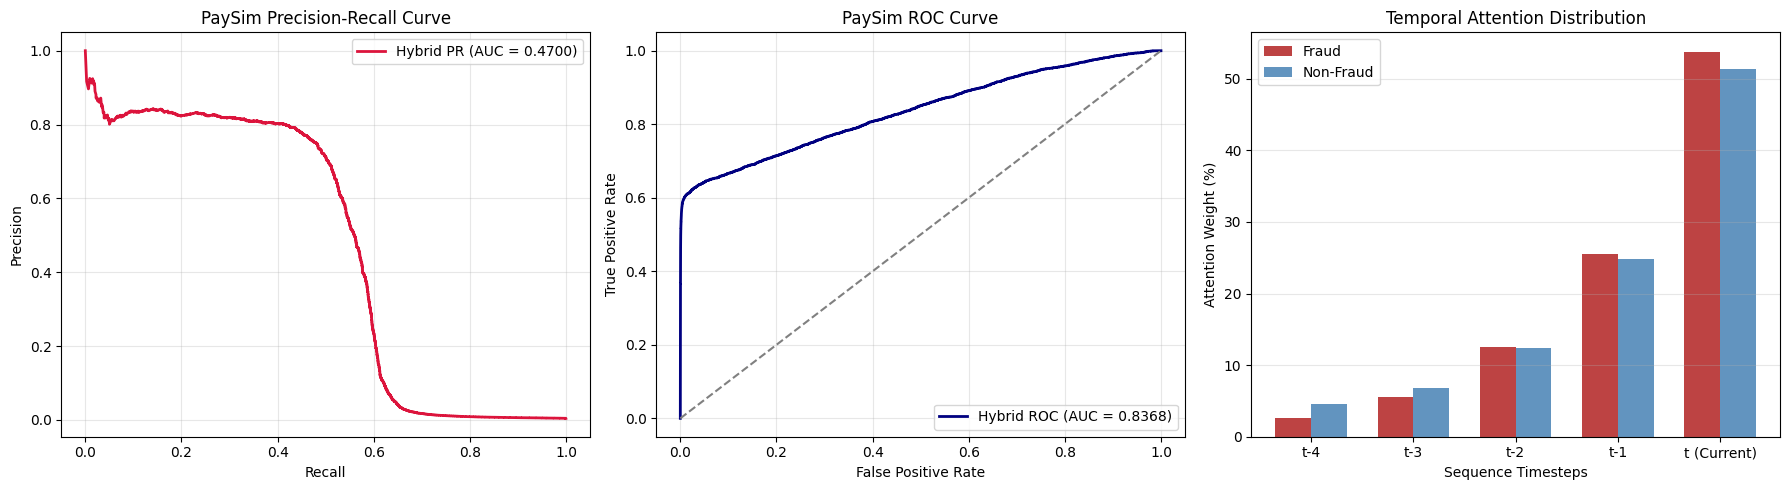

In [12]:
# ==============================================================================
# Step 9: Hybrid Test Evaluation & Temporal Attention Analysis (XAI)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    classification_report
)

# --- 1. Load Best Hybrid Model & Run Test Inference ---
hybrid_model.load_state_dict(torch.load("best_paysim_hybrid.pt"))
hybrid_model.eval()

test_preds = []
test_targets = []
test_attn_weights = []

with torch.no_grad():
    for Xb, yb in te_loader:
        Xb = Xb.to(device, non_blocking=True)
        logits, attn_w = hybrid_model(Xb)
        probs = torch.sigmoid(logits.squeeze(-1)).cpu().numpy()

        test_preds.extend(probs)
        test_targets.extend(yb.numpy())
        test_attn_weights.append(attn_w.squeeze(-1).cpu().numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)
test_attn_weights = np.concatenate(test_attn_weights, axis=0)

# --- 2. Calculate Evaluation Metrics ---
hybrid_test_prauc = average_precision_score(test_targets, test_preds)
hybrid_test_rocauc = roc_auc_score(test_targets, test_preds)

print("================ Hybrid (LSTM + Attention) Test Set Results ================")
print(f"Hybrid Test PR-AUC  : {hybrid_test_prauc:.4f}")
print(f"Hybrid Test ROC-AUC : {hybrid_test_rocauc:.4f}")

binary_preds = (test_preds >= 0.5).astype(int)
print("\nClassification Report (Threshold = 0.5):")
print(classification_report(test_targets, binary_preds, digits=4))

# --- 3. Attention Weight Distribution (XAI) ---
fraud_indices = np.where(test_targets == 1)[0]
non_fraud_indices = np.where(test_targets == 0)[0]

mean_attn_fraud = test_attn_weights[fraud_indices].mean(axis=0)
mean_attn_non_fraud = test_attn_weights[non_fraud_indices].mean(axis=0)

timesteps = [f"t-{4-i}" if 4-i > 0 else "t (Current)" for i in range(5)]

print("\n================ Temporal Attention Distribution ================")
for t_label, w_fraud, w_non in zip(timesteps, mean_attn_fraud, mean_attn_non_fraud):
    print(f"Timestep {t_label:12s} | Fraud Attention: {w_fraud*100:6.2f}% | Non-Fraud Attention: {w_non*100:6.2f}%")

# --- 4. Plot Comparison: PR/ROC Curves and Attention Weights ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: PR Curve
precision, recall, _ = precision_recall_curve(test_targets, test_preds)
axes[0].plot(recall, precision, color="crimson", lw=2, label=f"Hybrid PR (AUC = {hybrid_test_prauc:.4f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("PaySim Precision-Recall Curve")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Subplot 2: ROC Curve
fpr, tpr, _ = roc_curve(test_targets, test_preds)
axes[1].plot(fpr, tpr, color="navy", lw=2, label=f"Hybrid ROC (AUC = {hybrid_test_rocauc:.4f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("PaySim ROC Curve")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

# Subplot 3: Attention Weights Bar Chart
x_pos = np.arange(len(timesteps))
bar_w = 0.35
axes[2].bar(x_pos - bar_w/2, mean_attn_fraud * 100, width=bar_w, label="Fraud", color="firebrick", alpha=0.85)
axes[2].bar(x_pos + bar_w/2, mean_attn_non_fraud * 100, width=bar_w, label="Non-Fraud", color="steelblue", alpha=0.85)
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(timesteps)
axes[2].set_xlabel("Sequence Timesteps")
axes[2].set_ylabel("Attention Weight (%)")
axes[2].set_title("Temporal Attention Distribution")
axes[2].legend()
axes[2].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("paysim_hybrid_evaluation_and_attention.png", dpi=300)
plt.show()
